# 01 — Curva epidemiológica e sinais de alerta

Vamos transformar notificações semanais em uma leitura temporal, usando média móvel e um limiar didático.

In [1]:
from pathlib import Path
import sys, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
ROOT=Path.cwd().parent if Path.cwd().name=="notebooks" else Path.cwd()
sys.path.insert(0,str(ROOT))
from scripts.carregar_dados import caminhos
arq_casos, _, FONTE = caminhos()
df=pd.read_csv(arq_casos,parse_dates=["semana"])
print("Fonte selecionada:",FONTE)
it=df.query("municipio == 'Itumbiara'").sort_values("semana").copy()
if it.empty: raise ValueError("Itumbiara não foi encontrada na base selecionada.")
it["media_4s"]=it.casos.rolling(4,min_periods=1).mean()
baseline=it.casos.iloc[:min(10,len(it))]


limiar=baseline.mean()+2*baseline.std()

it["alerta"]=it.media_4s>limiar
it.tail()

Fonte selecionada: SINAN/DATASUS + IBGE (dados oficiais agregados)


,codigo_ibge,municipio,semana,casos,media_4s,alerta
3857,5211503.0,Itumbiara,2024-11-17,3,1.75,False
3858,5211503.0,Itumbiara,2024-11-24,5,2.75,False
3859,5211503.0,Itumbiara,2024-12-01,3,3.00,False
3860,5211503.0,Itumbiara,2024-12-08,3,3.50,False
3861,5211503.0,Itumbiara,2024-12-15,2,3.25,False


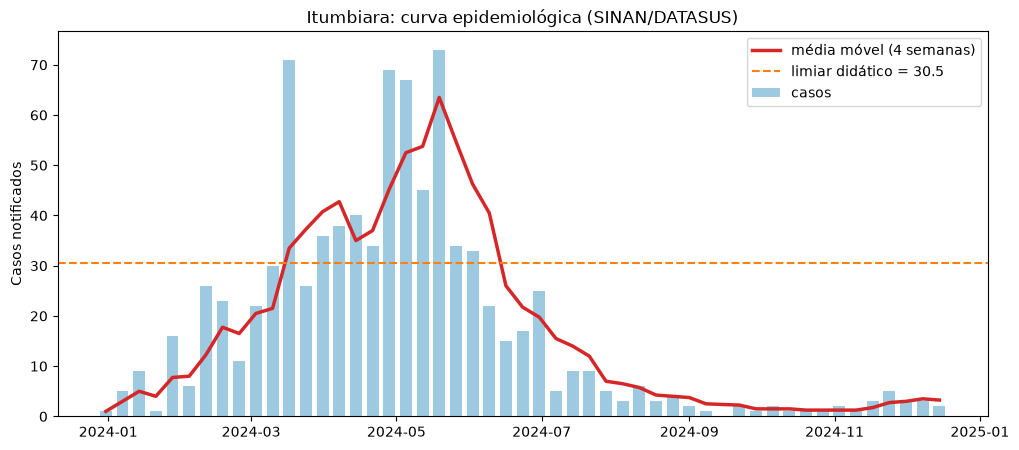

In [2]:
fig,ax=plt.subplots(figsize=(12,5))
ax.bar(it.semana,it.casos,width=5,color="#9ecae1",label="casos")
ax.plot(it.semana,it.media_4s,color="#d62728",lw=2.5,label="média móvel (4 semanas)")
ax.axhline(limiar,color="#ff7f0e",ls="--",label=f"limiar didático = {limiar:.1f}")
ax.set(title="Itumbiara: curva epidemiológica (SINAN/DATASUS)",ylabel="Casos notificados",xlabel="")
ax.legend(); plt.show()

In [3]:
it.loc[it.alerta,["semana","casos","media_4s"]].head(10)

,semana,casos,media_4s
3823,2024-03-17,71,33.50
3824,2024-03-24,26,37.25
3825,2024-03-31,36,40.75
3826,2024-04-07,38,42.75
3827,2024-04-14,40,35.00
3828,2024-04-21,34,37.00
3829,2024-04-28,69,45.25
3830,2024-05-05,67,52.50
3831,2024-05-12,45,53.75
3832,2024-05-19,73,63.50


### Cuidado de interpretação

Dados do limiar acima é pedagógico.

A análise real deve considerar atraso de notificação, sazonalidade, definição de caso, população exposta e protocolos epidemiológicos.